# Part 3 Showcase: Build a casino simulator 🎰

**Uses:** Lectures 5-8 - lists, sets, slicing, loops, **functions** (L07), **dictionaries** and **debugging** (L08).

**What you will build, from the simplest game to the hardest:**
1. **Roulette** - a wheel with 37 pockets. Why does one green zero make the casino rich?
2. **A deck of cards** - 52 cards from a loop inside a loop
3. **War** - the simplest card game: higher card wins. One small rule change, and the casino wins.
4. **Blackjack** - get close to 21. 100,000 rounds: which strategy loses the least?
5. **Poker** - name every hand, catch a bug with tests, and compare 100,000 hands with the exact math
6. **The scoreboard** - how much does the casino keep in each game?

> 🐍 **Pip says:** "Never been to a casino? Perfect. You only need to know how to count - and Python counts for you."

*This notebook is about math and code, not about gambling. Spoiler: in every casino game, the player loses money in the long run. We will **prove** it.*

## 0. Borrow three toolboxes

`random` spins the wheel and shuffles the cards, `math` does the exact math, and `matplotlib` draws the charts. Getting a toolbox is called `import` - **you will learn it in Lectures 9-10. For now, just run it.**

`random.seed(7)` makes the "random" results the same every time you run the notebook, so your numbers match the slides.

In [1]:
import random                     # random numbers, shuffling (Lecture 9 - just run it)
import math                       # exact math helpers
import matplotlib.pyplot as plt   # drawing toolbox (Lecture 10 - just run it)
random.seed(7)                    # same "random" results every run

## 1. Roulette: the simplest casino game

**European roulette** has 37 pockets, numbered 0 to 36:
- 18 **red** pockets
- 18 **black** pockets
- **one green zero** (pocket 0)

The ball lands in one pocket at random. The red numbers are a **set** (Lecture 5) - checking `in` a set is fast and easy.

In [2]:
RED = {1, 3, 5, 7, 9, 12, 14, 16, 18, 19, 21, 23, 25, 27, 30, 32, 34, 36}

def color(pocket):
    if pocket == 0:
        return "green"
    if pocket in RED:
        return "red"
    return "black"

def spin():
    return random.randint(0, 36)      # one of the 37 pockets (just run it)

for i in range(8):
    pocket = spin()
    print(pocket, color(pocket))

20 black
9 red
25 red
3 red
4 black
34 red
6 black
23 red


### Is the wheel fair? Count 37,000 spins

The counting pattern from Lecture 8: `counts.get(key, 0) + 1`. If every pocket is equally likely, we expect about 18,000 red, 18,000 black and 1,000 green.

In [3]:
color_counts = {}
for i in range(37000):
    c = color(spin())
    color_counts[c] = color_counts.get(c, 0) + 1
print(color_counts)

{'red': 18160, 'black': 17850, 'green': 990}


### Bet on red

You bet 10 ILS on red:
- red → you **win** 10 ILS
- black **or green** → you **lose** 10 ILS

The function returns how much money you **gain** (a minus sign means you lost).

In [4]:
def bet_on_red(bet=10):
    if color(spin()) == "red":
        return bet          # you win
    return -bet             # black or green: you lose

results = []
for i in range(10):
    results.append(bet_on_red())
print(results)
print("Total after 10 bets:", sum(results), "ILS")

[10, 10, 10, -10, 10, 10, 10, -10, -10, -10]
Total after 10 bets: 20 ILS


### The math, without any fancy math

Imagine the wheel lands **once on every pocket** (37 spins, 10 ILS each):

| Pockets | How many | You get |
|---|---|---|
| red | 18 | +10 each → **+180** |
| black | 18 | -10 each → **-180** |
| green 0 | 1 | -10 → **-10** |
| **Total** | 37 spins | **-10 ILS** |

So on average you lose **10 ILS every 37 spins** = 10/37 ≈ 0.27 ILS per 10 ILS bet. That is **2.7%** - the **house edge**. Without the green zero the game would be perfectly fair. The zero is the casino's secret weapon.

In [5]:
def play(num_spins, money=1000):
    history = [money]                  # money after each spin
    for i in range(num_spins):
        money = money + bet_on_red()
        history.append(money)
    return history

print(play(10))

[1000, 990, 980, 990, 1000, 990, 1000, 1010, 1020, 1010, 1020]


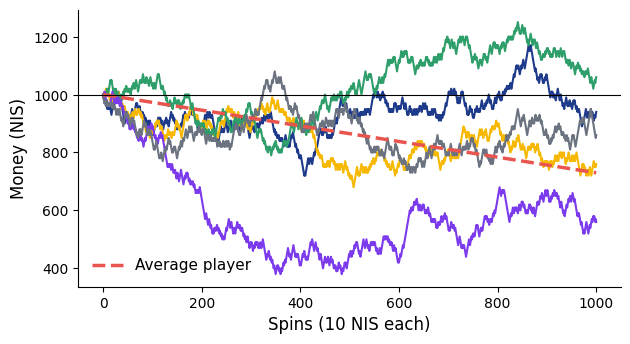

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
colors = ["#1E3A8A", "#F6B800", "#2E9E6B", "#7C3AED", "#6B7280"]
for player in range(5):                                  # 5 players, 1000 spins each
    ax.plot(play(1000), color=colors[player], linewidth=1.5)
average = []
for i in range(1001):
    average.append(1000 - i * 10 / 37)                   # lose 10/37 ILS per spin, on average
ax.plot(average, color="#E8554E", linestyle="--", linewidth=2.5, label="Average player")
ax.axhline(1000, color="black", linewidth=0.8)
ax.set_xlabel("Spins (10 ILS each)", fontsize=12)
ax.set_ylabel("Money (ILS)", fontsize=12)
ax.legend(fontsize=11, frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Some players get lucky for a while. But the **average** keeps going down. Now look from the casino's side: a **million** bets of 10 ILS from all its players. (A few seconds - the intern is spinning a million times!)

In [7]:
NUM_BETS = 1000000
casino_profit = 0
for i in range(NUM_BETS):
    casino_profit = casino_profit - bet_on_red()     # what you lose, the casino wins

print("Casino profit:", casino_profit, "ILS")
print("Per 10 ILS bet:", casino_profit / NUM_BETS, "ILS")
print("The math says:", round(10 / 37, 4), "ILS")
roulette_edge = 100 * casino_profit / (10 * NUM_BETS)  # % of all the money bet
print(f"House edge: {roulette_edge:.2f}%  (math: {100 / 37:.2f}%)")

Casino profit: 282440 ILS
Per 10 ILS bet: 0.28244 ILS
The math says: 0.2703 ILS
House edge: 2.82%  (math: 2.70%)


### Experiment 1: a different bet, the same edge

Bet 10 ILS on **one number** (say 7). If the ball lands on 7, you win **35 times** your bet (350 ILS). Otherwise you lose 10.

Count again with one spin per pocket: 1 win (+350) and 36 losses (-360) → **-10 ILS every 37 spins**. The same 2.7%!

But the ride is very different. Watch:

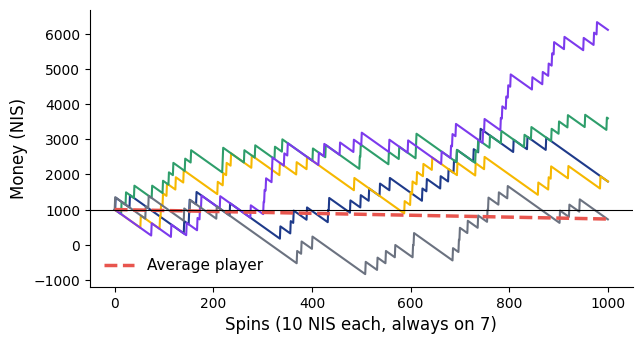

In [8]:
def bet_on_number(number=7, bet=10):
    if spin() == number:
        return 35 * bet     # big win!
    return -bet

def play_number(num_spins, money=1000):
    history = [money]
    for i in range(num_spins):
        money = money + bet_on_number()
        history.append(money)
    return history

fig, ax = plt.subplots(figsize=(7, 3.6))
for player in range(5):
    ax.plot(play_number(1000), color=colors[player], linewidth=1.5)
ax.plot(average, color="#E8554E", linestyle="--", linewidth=2.5, label="Average player")
ax.axhline(1000, color="black", linewidth=0.8)
ax.set_xlabel("Spins (10 ILS each, always on 7)", fontsize=12)
ax.set_ylabel("Money (ILS)", fontsize=12)
ax.legend(fontsize=11, frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Big jumps up, long slides down. Some players are way up, some are way down - but the **average** line is exactly the same as betting on red. **Changing the bet changes the excitement, not the edge.**

### Experiment 2: the "can't lose" doubling trick

A famous idea: bet 10 on red. If you lose, **double** the bet (20, then 40, 80...). When you finally win, you get back everything you lost **plus 10**. Then start again at 10.

You stop when you are **100 ILS up** (a good night!) or when the money is gone. Can this beat the casino? A `while` loop (Lecture 6) plays one night:

In [9]:
def doubling_night(money=1000, goal=1100):
    bet = 10
    while 0 < money < goal:
        if bet > money:
            bet = money                 # can't bet money you don't have
        result = bet_on_red(bet)
        money = money + result
        if result > 0:
            bet = 10                    # won: start again
        else:
            bet = bet * 2               # lost: double it
    return money

print(doubling_night())
print(doubling_night())
print(doubling_night())

1100
1100
1100


In [10]:
NUM_NIGHTS = 10000
good_nights = 0
total_money = 0
for night in range(NUM_NIGHTS):
    money = doubling_night()
    if money >= 1100:
        good_nights = good_nights + 1
    total_money = total_money + money

print(f"Good nights (+100 ILS): {100 * good_nights / NUM_NIGHTS:.1f}%")
print(f"Lost everything:        {100 * (NUM_NIGHTS - good_nights) / NUM_NIGHTS:.1f}%")
print(f"Average money at the end of a night: {total_money / NUM_NIGHTS:.0f} ILS  (started with 1000)")

Good nights (+100 ILS): 88.8%
Lost everything:        11.2%
Average money at the end of a night: 977 ILS  (started with 1000)


😮 Most nights you go home **happy**. But a few nights you lose about 7 times in a row (10 + 20 + 40 + 80 + 160 + 320 + ...), and the doubled bet eats **all 1000 ILS**. Those rare disasters are bigger than all the small wins together: the average night still **loses money**.

**No betting trick can beat the house edge.** Every single bet loses 2.7% on average, so any mix of bets does too.

> **Try this**
> - **American roulette** has 38 pockets: an extra green **00**. Change `spin()` to `random.randint(0, 37)` and treat 37 as green. Run the million bets again. What is the house edge now? (Math: 2/38 = 5.26%)
> - Change the doubling goal to 1500. What happens to the good nights? And to the average?

## 2. Build a deck of cards

Time to leave the wheel and pick up cards. A card is just a short **string**: rank + suit. `"AS"` is the Ace of Spades, `"10H"` is the Ten of Hearts.

| Letter | Suit |
|---|---|
| `S` | Spades ♠ |
| `H` | Hearts ♥ |
| `D` | Diamonds ♦ |
| `C` | Clubs ♣ |

13 ranks × 4 suits = 52 cards. A **loop inside a loop** (Lecture 8) builds them all.

In [11]:
RANKS = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "J", "Q", "K", "A"]
SUITS = ["S", "H", "D", "C"]

def make_deck():
    deck = []
    for suit in SUITS:            # outer loop: 4 suits
        for rank in RANKS:        # inner loop: 13 ranks
            deck.append(rank + suit)
    return deck

deck = make_deck()
print(len(deck), "cards")
print(deck[:13])

52 cards
['2S', '3S', '4S', '5S', '6S', '7S', '8S', '9S', '10S', 'JS', 'QS', 'KS', 'AS']


Let's make them pretty with a **dictionary** from suit letter to symbol. The suit is the **last** character of the card (`card[-1]`), and the rank is everything before it (`card[:-1]`) - slicing from Lecture 5. This works for `"10H"` too, which has 3 characters!

In [12]:
SYMBOLS = {"S": "♠", "H": "♥", "D": "♦", "C": "♣"}

def pretty(card):
    rank = card[:-1]          # everything except the last character
    suit = card[-1]           # the last character
    return rank + SYMBOLS[suit]

def pretty_hand(hand):
    text = ""
    for card in hand:
        text = text + pretty(card) + " "
    return text

for row in range(4):          # 4 rows, one per suit
    print(pretty_hand(deck[row * 13:(row + 1) * 13]))

2♠ 3♠ 4♠ 5♠ 6♠ 7♠ 8♠ 9♠ 10♠ J♠ Q♠ K♠ A♠ 
2♥ 3♥ 4♥ 5♥ 6♥ 7♥ 8♥ 9♥ 10♥ J♥ Q♥ K♥ A♥ 
2♦ 3♦ 4♦ 5♦ 6♦ 7♦ 8♦ 9♦ 10♦ J♦ Q♦ K♦ A♦ 
2♣ 3♣ 4♣ 5♣ 6♣ 7♣ 8♣ 9♣ 10♣ J♣ Q♣ K♣ A♣ 


### Shuffle and deal

`random.shuffle(deck)` mixes the list, like shuffling real cards. Then we take the top cards with slicing.

In [13]:
def deal(deck, how_many):
    random.shuffle(deck)          # mix the whole deck
    return deck[:how_many]        # take cards from the top

hand = deal(deck, 5)
print(hand)
print(pretty_hand(hand))

['JD', '4H', '7D', '6D', '3C']
J♦ 4♥ 7♦ 6♦ 3♣ 


### Draw the cards

A little drawing helper. It uses more **matplotlib** - **just run it.**

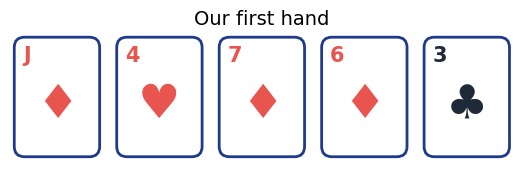

In [14]:
from matplotlib.patches import FancyBboxPatch   # rounded rectangles (just run it)

def show_hand(hand, title=""):
    fig, ax = plt.subplots(figsize=(1.3 * len(hand), 2.3))
    for i in range(len(hand)):
        rank = hand[i][:-1]
        suit = hand[i][-1]
        color = "#1F2937"                       # black for spades and clubs
        if suit == "H" or suit == "D":
            color = "#E8554E"                   # red for hearts and diamonds
        x = i * 1.2                             # where this card starts
        ax.add_patch(FancyBboxPatch((x, 0), 1, 1.4, boxstyle="round,pad=0,rounding_size=0.12",
                                    facecolor="white", edgecolor="#1E3A8A", linewidth=2))
        ax.text(x + 0.1, 1.3, rank, fontsize=15, color=color, weight="bold", va="top")
        ax.text(x + 0.5, 0.6, SYMBOLS[suit], fontsize=34, color=color, ha="center", va="center")
    ax.set_xlim(-0.05, 1.2 * len(hand) - 0.15)
    ax.set_ylim(-0.05, 1.45)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=14)
    plt.show()

show_hand(hand, "Our first hand")

## 3. War: the simplest card game

You and the dealer each get **one card**. The **higher** card wins. That's it!

### Which card is higher? Careful!

Let's ask Python to compare the ranks directly:

In [15]:
print("10" > "9")
print("K" > "A")
print(sorted(["10", "9", "A", "K", "2"]))

False
True
['10', '2', '9', 'A', 'K']


😱 Python compares **text** like a dictionary: letter by letter. `"1"` comes before `"9"`, and `"K"` comes after `"A"`. That is not card order!

**Fix:** a dictionary that turns each rank into a **number**: 2 → 2, ..., J → 11, Q → 12, K → 13, A → 14. The position in `RANKS` already has the right order.

In [16]:
VALUES = {}
for i in range(len(RANKS)):
    VALUES[RANKS[i]] = i + 2       # "2" -> 2, ..., "A" -> 14
print(VALUES)

def value(card):
    return VALUES[card[:-1]]

print(value("10H") > value("9S"))
print(value("KD") > value("AC"))

{'2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9, '10': 10, 'J': 11, 'Q': 12, 'K': 13, 'A': 14}
True
False


In [17]:
def war_round():
    cards = deal(deck, 2)
    you = cards[0]
    dealer = cards[1]
    if value(you) > value(dealer):
        return "you", you, dealer
    if value(dealer) > value(you):
        return "dealer", you, dealer
    return "tie", you, dealer

for i in range(6):
    winner, you, dealer = war_round()
    print("You:", pretty(you), "  Dealer:", pretty(dealer), "  ->", winner)

You: 5♥   Dealer: A♥   -> dealer
You: 10♠   Dealer: A♠   -> dealer
You: 5♦   Dealer: A♠   -> dealer
You: 4♠   Dealer: 6♥   -> dealer
You: J♦   Dealer: K♦   -> dealer
You: 9♣   Dealer: 5♥   -> you


### Is it fair? 100,000 rounds

In [18]:
war_counts = {}
for i in range(100000):
    winner, you, dealer = war_round()
    war_counts[winner] = war_counts.get(winner, 0) + 1
print(war_counts)

{'dealer': 46985, 'you': 47172, 'tie': 5843}


You and the dealer win **equally often** ✅. A fair game - so no casino would offer it!

**Ties:** after your card, 51 cards are left and **3** of them have your rank. So a tie happens 3/51 ≈ 5.9% of the time. Check the count above: about 5,900 out of 100,000.

### Casino War: one tiny rule

Casinos offer this game with one extra rule: **if it's a tie, the casino wins.** (The real rule is a bit more complicated, but the idea is the same.) Bet 10 ILS per round:

In [19]:
def casino_war(bet=10):
    winner, you, dealer = war_round()
    if winner == "you":
        return bet
    return -bet              # dealer wins AND ties go to the casino

NUM_ROUNDS = 100000
war_profit = 0
for i in range(NUM_ROUNDS):
    war_profit = war_profit - casino_war()

war_edge = 100 * war_profit / (10 * NUM_ROUNDS)
print("Casino profit after 100,000 rounds:", war_profit, "ILS")
print(f"House edge: {war_edge:.2f}%  (math: {100 * 3 / 51:.2f}%)")

Casino profit after 100,000 rounds: 57520 ILS
House edge: 5.75%  (math: 5.88%)


The game looks 50-50, and it **feels** fair: you win almost half the rounds! But the ties are the casino's "green zero" - and this edge (5.9%) is even **bigger** than roulette's.

> 🐍 **Pip says:** "Every casino game is a fair game plus one small rule. Find the small rule, and you found the casino's profit."

## 4. Blackjack: get close to 21

**Rules (simple version):**
- You and the dealer each get 2 cards.
- Cards 2-10 are worth their number. J, Q, K are worth **10**. An Ace is worth **11** - or **1** if 11 would take you over 21.
- You take more cards ("hit") as long as you want. Go **over 21** and you **bust**: you lose right away.
- Then the dealer plays with a fixed rule: **hit below 17, stop at 17 or more.**
- Closer to 21 wins. Same total is a tie (you get your bet back).

*Real blackjack has more options (doubling, splitting, 3:2 for a blackjack). We keep it simple.*

### Step 1: card points, with a dictionary

In [20]:
POINTS = {"J": 10, "Q": 10, "K": 10, "A": 11}
for rank in RANKS[:9]:             # "2" ... "10"
    POINTS[rank] = int(rank)
print(POINTS)

def hand_total(hand):
    total = 0
    for card in hand:
        total = total + POINTS[card[:-1]]
    return total

print(hand_total(["KS", "7D"]))
print(hand_total(["AS", "9H"]))

{'J': 10, 'Q': 10, 'K': 10, 'A': 11, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9, '10': 10}
17
20


### Step 2: a quick test... and a bug

An Ace, a King and a 5. The Ace should count as 1 here (11 + 10 + 5 = 26 is too much), so the answer should be **16**.

In [21]:
print(hand_total(["AS", "KD", "5H"]), "<- we expect 16")

26 <- we expect 16


🔍 **A logic bug** (Lecture 8): no error message, just a wrong answer. Our function always counts the Ace as 11.

**Fix:** count the Aces too. While the total is over 21 **and** we still have an Ace counted as 11, turn it into a 1 (subtract 10).

In [22]:
def hand_total(hand):
    total = 0
    aces = 0
    for card in hand:
        total = total + POINTS[card[:-1]]
        if card[:-1] == "A":
            aces = aces + 1
    while total > 21 and aces > 0:      # an Ace can drop from 11 to 1
        total = total - 10
        aces = aces - 1
    return total

print(hand_total(["AS", "KD", "5H"]), "<- we expect 16")
print(hand_total(["AS", "AD", "9H"]), "<- we expect 21")
print(hand_total(["AS", "KD"]), "<- we expect 21 (blackjack!)")

16 <- we expect 16
21 <- we expect 21
21 <- we expect 21 (blackjack!)


### Step 3: play one round

`stand_on` is **your strategy**: keep hitting until your total reaches this number. We deal the whole shuffled deck and take cards from it one by one with `pop(0)` (take the first item out of the list).

In [23]:
def blackjack_round(stand_on=17, show=False):
    cards = deal(deck, 52)               # a shuffled copy of the deck
    you = [cards.pop(0), cards.pop(0)]
    dealer = [cards.pop(0), cards.pop(0)]

    while hand_total(you) < stand_on:    # your turn
        you.append(cards.pop(0))
    if show:
        print("You:   ", pretty_hand(you), "=", hand_total(you))
    if hand_total(you) > 21:
        if show:
            print("You bust -> you lose")
        return -1                        # you bust: you lose right away

    while hand_total(dealer) < 17:       # dealer's turn: fixed rule
        dealer.append(cards.pop(0))
    if show:
        print("Dealer:", pretty_hand(dealer), "=", hand_total(dealer))

    if hand_total(dealer) > 21 or hand_total(you) > hand_total(dealer):
        result = 1
    elif hand_total(you) == hand_total(dealer):
        result = 0
    else:
        result = -1
    if show:
        print({1: "You win", 0: "Tie", -1: "Dealer wins"}[result])
    return result

for i in range(3):
    blackjack_round(show=True)
    print()

You:    3♦ 10♠ K♥  = 23
You bust -> you lose

You:    8♠ 9♦  = 17
Dealer: 4♠ 9♥ Q♥  = 23
You win

You:    7♣ A♠  = 18
Dealer: 10♥ A♦  = 21
Dealer wins



### Step 4: 100,000 rounds - copy the dealer

Easy strategy: play **exactly like the dealer** (stop at 17). Same rules for both sides... so it must be fair, right?

In [24]:
def house_edge(stand_on, rounds):
    casino = 0
    for i in range(rounds):
        casino = casino - blackjack_round(stand_on)
    return 100 * casino / rounds           # % of the money bet

copy_dealer_edge = house_edge(17, 100000)
print(f"Copy the dealer: house edge {copy_dealer_edge:.2f}%")

Copy the dealer: house edge 8.24%


Not fair at all! 🕵️ Where is the "small rule"? Look at the code again: **you play first**. If you bust, you lose **right away** - even if the dealer would have busted too. When **both** bust, the casino wins. Let's count how often that happens:

In [25]:
def both_bust(stand_on=17):
    cards = deal(deck, 52)
    you = [cards.pop(0), cards.pop(0)]
    dealer = [cards.pop(0), cards.pop(0)]
    while hand_total(you) < stand_on:
        you.append(cards.pop(0))
    while hand_total(dealer) < 17:
        dealer.append(cards.pop(0))
    return hand_total(you) > 21 and hand_total(dealer) > 21

count = 0
for i in range(100000):
    if both_bust():
        count = count + 1
print(f"Both bust in {100 * count / 100000:.2f}% of the rounds - and the casino wins every one of them")

Both bust in 7.96% of the rounds - and the casino wins every one of them


### Experiment 3: find the best strategy

Maybe stopping earlier is smarter (you bust less)? Try every `stand_on` from 12 to 20, with 20,000 rounds each.

In [26]:
strategies = []
edges = []
for stand_on in range(12, 21):
    edge = house_edge(stand_on, 20000)
    strategies.append(stand_on)
    edges.append(edge)
    print(f"Stand on {stand_on}: house edge {edge:5.2f}%")

Stand on 12: house edge  9.94%


Stand on 13: house edge  9.79%


Stand on 14: house edge  7.96%


Stand on 15: house edge  7.83%


Stand on 16: house edge  7.16%


Stand on 17: house edge  8.73%


Stand on 18: house edge 11.26%


Stand on 19: house edge 20.20%


Stand on 20: house edge 35.56%


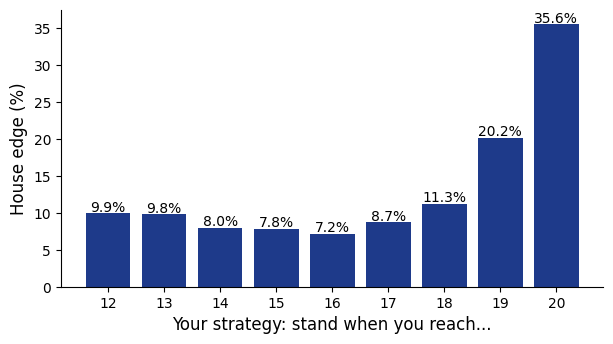

Best strategy: stand on 16 - and you still lose 7.16% per bet


In [27]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(strategies, edges, color="#1E3A8A")
for i in range(len(strategies)):
    ax.text(strategies[i], edges[i] + 0.3, f"{edges[i]:.1f}%", ha="center", fontsize=10)
ax.set_xticks(strategies)
ax.set_xlabel("Your strategy: stand when you reach...", fontsize=12)
ax.set_ylabel("House edge (%)", fontsize=12)
ax.set_ylim(0, max(edges) + 2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

best_edge = min(edges)
print("Best strategy: stand on", strategies[edges.index(best_edge)], f"- and you still lose {best_edge:.2f}% per bet")

**Every** bar is above zero: no simple strategy beats the casino. Playing smart makes you lose **less**, never win.

*Fun fact: with the full rules and a perfect strategy (a big table of "hit or stand" for every pair of cards), real blackjack has an edge of only about 0.5% - one of the lowest in the casino. Card counters try to beat even that, and casinos ask them to leave!*

> **Try this**
> - Make it fair: if **both** bust, call it a tie (`return 0`). Move the bust check after the dealer plays. Is the edge close to 0 now?
> - Let the dealer stop at 16 instead of 17. Is that better or worse for you?

## 5. Poker: the final boss 🃏

Poker is different: you play **against other players**, not against the casino. The casino just takes a small fee from every pot (called the *rake*). But poker has the most interesting math: how rare is each hand?

**Cheat sheet** (from the strongest to the weakest):

| Hand | What it means | Example |
|---|---|---|
| Straight flush | 5 in a row, all the same suit | 5♠ 6♠ 7♠ 8♠ 9♠ |
| Four of a kind | 4 cards of one rank | Q Q Q Q 3 |
| Full house | 3 of one rank + 2 of another | K K K 7 7 |
| Flush | all 5 the same suit | 2♥ 4♥ 6♥ 9♥ J♥ |
| Straight | 5 ranks in a row (any suits) | 9 10 J Q K |
| Three of a kind | 3 of one rank | 8 8 8 K 2 |
| Two pair | 2 + 2 | J J 4 4 A |
| Pair | 2 of one rank | 10 10 6 2 9 |
| High card | none of the above | A J 8 6 2 |

*To keep it simple, the famous "royal flush" (10-J-Q-K-A, one suit) is counted as a straight flush - it is just the best one.*

### Step 1: count the ranks with a dictionary

The same counting pattern as the roulette colors: `counts.get(rank, 0) + 1`.

In [28]:
def count_ranks(hand):
    counts = {}
    for card in hand:
        rank = card[:-1]
        counts[rank] = counts.get(rank, 0) + 1
    return counts

full_house = ["KH", "KS", "7D", "7C", "KD"]
print(count_ranks(full_house))
print(sorted(count_ranks(full_house).values()))

{'K': 3, '7': 2}
[2, 3]


### The "shape" of a hand

We do not care **which** ranks repeat, only **how many times**. Sort the counts and you get the shape:

| Sorted counts | Hand |
|---|---|
| `[1, 4]` | Four of a kind |
| `[2, 3]` | Full house |
| `[1, 1, 3]` | Three of a kind |
| `[1, 2, 2]` | Two pair |
| `[1, 1, 1, 2]` | Pair |
| `[1, 1, 1, 1, 1]` | maybe a straight or a flush... or just high card |

### Step 2: flush (with a set) and straight (with `VALUES`)

A **set** keeps no duplicates: if the 5 suits make a set of size **1**, it is a flush. For a straight we reuse `VALUES` from the War game - 5 **different** numbers, and the biggest minus the smallest is exactly 4.

In [29]:
def is_flush(hand):
    suits = set()
    for card in hand:
        suits.add(card[-1])      # the suit letter
    return len(suits) == 1       # one suit only?

def rank_values(hand):
    values = []
    for card in hand:
        values.append(value(card))
    return sorted(values)

def is_straight(hand):
    values = rank_values(hand)
    different = len(set(values)) == 5          # no repeated ranks
    return different and values[4] - values[0] == 4

print(is_flush(["2H", "9H", "JH", "4H", "6H"]), is_flush(full_house))
print(is_straight(["9S", "10D", "JC", "QH", "KS"]), is_straight(["9S", "10D", "JC", "QH", "AS"]))

True False
True False


### Step 3: one function to name them all

`hand_name` checks from the **strongest** hand down. The first match wins - that's why the order of the `if`s matters (a straight flush is also a flush!).

In [30]:
def hand_name(hand):
    shape = sorted(count_ranks(hand).values())
    straight = is_straight(hand)
    flush = is_flush(hand)
    if straight and flush:
        return "Straight flush"
    if shape == [1, 4]:
        return "Four of a kind"
    if shape == [2, 3]:
        return "Full house"
    if flush:
        return "Flush"
    if straight:
        return "Straight"
    if shape == [1, 1, 3]:
        return "Three of a kind"
    if shape == [1, 2, 2]:
        return "Two pair"
    if shape == [1, 1, 1, 2]:
        return "Pair"
    return "High card"

print(hand_name(full_house))
print(hand_name(hand), "<- our first random hand")

Full house
High card <- our first random hand


### Step 4: test it like a pro

Programmers don't just *hope* the code works. They write **tests**: example inputs with the answer we **expect**, and let the computer check them all (Lecture 8).

One special case: in poker, **A-2-3-4-5** is also a straight (the Ace can be low - just like in blackjack!). Does our code know that?

In [31]:
TESTS = [
    [["5S", "6S", "7S", "8S", "9S"], "Straight flush"],
    [["QS", "QH", "QD", "QC", "3H"], "Four of a kind"],
    [["KH", "KS", "7D", "7C", "KD"], "Full house"],
    [["2H", "9H", "JH", "4H", "6H"], "Flush"],
    [["9S", "10D", "JC", "QH", "KS"], "Straight"],
    [["AS", "2D", "3C", "4H", "5S"], "Straight"],      # the Ace is low here!
    [["8S", "8H", "8D", "KC", "2H"], "Three of a kind"],
    [["JS", "JH", "4D", "4C", "AH"], "Two pair"],
    [["10S", "10H", "6D", "2C", "9H"], "Pair"],
    [["AS", "JD", "8C", "6H", "2S"], "High card"],
]

def run_tests():
    passed = 0
    for test in TESTS:
        got = hand_name(test[0])
        if got == test[1]:
            passed = passed + 1
        else:
            print("FAIL", test[0], "expected", test[1], "but got", got)
    print(passed, "of", len(TESTS), "tests passed")

run_tests()

FAIL ['AS', '2D', '3C', '4H', '5S'] expected Straight but got High card
9 of 10 tests passed


### Debugging: make the intern talk

Print the values that `is_straight` sees:

In [32]:
wheel = ["AS", "2D", "3C", "4H", "5S"]
values = rank_values(wheel)
print(values)
print(values[4] - values[0])      # biggest minus smallest

[2, 3, 4, 5, 14]
12


🔍 **Found it!** The Ace is worth 14, so 14 - 2 = 12, not 4. In A-2-3-4-5 the Ace should count as **1**.

**Fix:** one extra `if` for this special case. Since `hand_name` calls `is_straight` by its name, it automatically uses the new version!

In [33]:
def is_straight(hand):
    values = rank_values(hand)
    if values == [2, 3, 4, 5, 14]:             # A-2-3-4-5: the Ace is low
        return True
    different = len(set(values)) == 5
    return different and values[4] - values[0] == 4

run_tests()

10 of 10 tests passed


✅ All tests pass. Now we trust `hand_name` enough to run it 100,000 times.

### Step 5: simulate 100,000 hands

Deal a hand, name it, count it in a dictionary. (A few seconds - the intern is shuffling 100,000 decks!)

In [34]:
STRENGTH = {"High card": 1, "Pair": 2, "Two pair": 3, "Three of a kind": 4, "Straight": 5,
            "Flush": 6, "Full house": 7, "Four of a kind": 8, "Straight flush": 9}

NUM_HANDS = 100000
sim_counts = {}
for i in range(NUM_HANDS):
    name = hand_name(deal(deck, 5))
    sim_counts[name] = sim_counts.get(name, 0) + 1

for name in STRENGTH:
    print(name, sim_counts.get(name, 0))

High card 50207
Pair 42222
Two pair 4708
Three of a kind 2132
Straight 358
Flush 181
Full house 162
Four of a kind 27
Straight flush 3


### The exact answer

How many different 5-card hands exist, and how many of each kind? Mathematicians count this with **combinations**: `math.comb(n, k)` = the number of ways to choose `k` things out of `n`.

**Treat the formulas below as a black box: the math gives us these counts.** (If you are curious, ask an AI to explain one line - then check it!)

In [35]:
total = math.comb(52, 5)        # all possible 5-card hands
exact_counts = {
    "Straight flush": 10 * 4,
    "Four of a kind": 13 * 48,
    "Full house": 13 * math.comb(4, 3) * 12 * math.comb(4, 2),
    "Flush": 4 * math.comb(13, 5) - 40,
    "Straight": 10 * 4 ** 5 - 40,
    "Three of a kind": 13 * math.comb(4, 3) * math.comb(12, 2) * 4 * 4,
    "Two pair": math.comb(13, 2) * math.comb(4, 2) ** 2 * 11 * 4,
    "Pair": 13 * math.comb(4, 2) * math.comb(12, 3) * 4 ** 3,
}
exact_counts["High card"] = total - sum(exact_counts.values())   # all the rest

print("All 5-card hands:", total)
print(f"{'Hand':16}{'Simulated %':>12}{'Exact %':>10}{'About 1 in':>12}")
for name in STRENGTH:
    sim_pct = 100 * sim_counts.get(name, 0) / NUM_HANDS
    exact_pct = 100 * exact_counts[name] / total
    one_in = round(total / exact_counts[name])
    print(f"{name:16}{sim_pct:12.3f}{exact_pct:10.4f}{one_in:12}")

All 5-card hands: 2598960
Hand             Simulated %   Exact %  About 1 in
High card             50.207   50.1177           2
Pair                  42.222   42.2569           2
Two pair               4.708    4.7539          21
Three of a kind        2.132    2.1128          47
Straight               0.358    0.3925         255
Flush                  0.181    0.1965         509
Full house             0.162    0.1441         694
Four of a kind         0.027    0.0240        4165
Straight flush         0.003    0.0015       64974


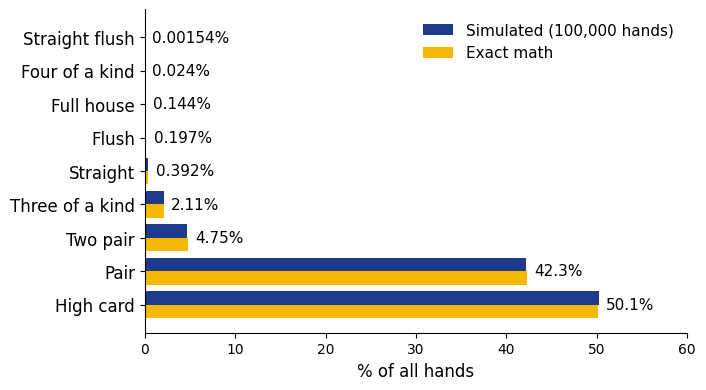

In [36]:
names = []
sim_pcts = []
exact_pcts = []
rows = []                       # 0, 1, 2, ... one row per hand name
for name in STRENGTH:
    rows.append(len(names))
    names.append(name)
    sim_pcts.append(100 * sim_counts.get(name, 0) / NUM_HANDS)
    exact_pcts.append(100 * exact_counts[name] / total)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(rows, sim_pcts, height=0.4, align="edge", color="#1E3A8A", label="Simulated (100,000 hands)")
ax.barh(rows, exact_pcts, height=-0.4, align="edge", color="#F6B800", label="Exact math")
for i in rows:
    ax.text(max(sim_pcts[i], exact_pcts[i]) + 0.8, i, f"{exact_pcts[i]:.3g}%", va="center", fontsize=11)
ax.set_yticks(rows)
ax.set_yticklabels(names, fontsize=12)
ax.set_xlabel("% of all hands", fontsize=12)
ax.set_xlim(0, 60)
ax.legend(fontsize=11, loc="upper right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

The blue and yellow bars are almost the same length. 🎉 **100,000 random tries ≈ the exact math.** This is the **Monte Carlo** idea from the Part 2 showcase: when the math is hard, try it many times at random and count.

### Mini-game: who wins?

Deal 10 cards: the first 5 go to Player 1, the next 5 to Player 2. The stronger hand name wins. *Keeping it simple:* the same kind of hand (say, both a Pair) is a tie. Real poker compares the cards - that's a spicy challenge below!

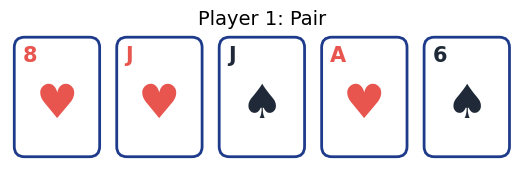

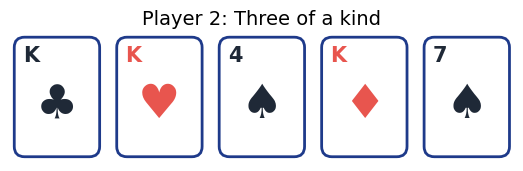

Winner: Player 2


In [37]:
def winner(hand1, hand2):
    strength1 = STRENGTH[hand_name(hand1)]
    strength2 = STRENGTH[hand_name(hand2)]
    if strength1 > strength2:
        return "Player 1"
    elif strength2 > strength1:
        return "Player 2"
    return "Tie"

cards = deal(deck, 10)
show_hand(cards[:5], "Player 1: " + hand_name(cards[:5]))
show_hand(cards[5:], "Player 2: " + hand_name(cards[5:]))
print("Winner:", winner(cards[:5], cards[5:]))

## 6. The scoreboard: how much does the casino keep?

We measured every house edge with our own simulations. Let's put them side by side: **out of every 100 ILS you bet, how much stays in the casino?**

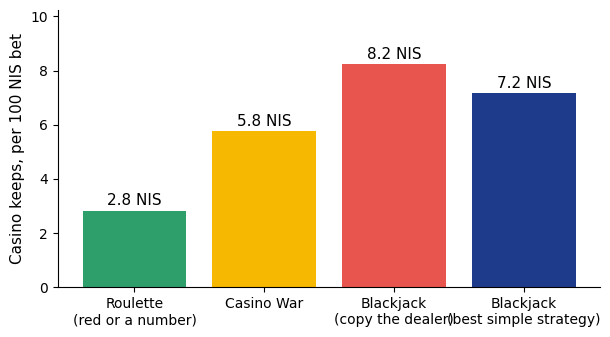

In [38]:
games = ["Roulette\n(red or a number)", "Casino War", "Blackjack\n(copy the dealer)", "Blackjack\n(best simple strategy)"]
game_edges = [roulette_edge, war_edge, copy_dealer_edge, best_edge]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(range(len(games)), game_edges, color=["#2E9E6B", "#F6B800", "#E8554E", "#1E3A8A"])
for i in range(len(games)):
    ax.text(i, game_edges[i] + 0.2, f"{game_edges[i]:.1f} ILS", ha="center", fontsize=11)
ax.set_xticks(range(len(games)))
ax.set_xticklabels(games, fontsize=10)
ax.set_ylabel("Casino keeps, per 100 ILS bet", fontsize=11)
ax.set_ylim(0, max(game_edges) + 2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

A few ILS per 100 sounds tiny. But a night at the casino is **many** bets. Here is what 100 bets of 10 ILS (1,000 ILS of betting) cost in each game, **on average**:

In [39]:
for i in range(len(games)):
    name = games[i].replace("\n", " ")
    print(f"{name:38} {100 * 10 * game_edges[i] / 100:6.0f} ILS lost after 100 bets of 10 ILS")

Roulette (red or a number)                 28 ILS lost after 100 bets of 10 ILS
Casino War                                 58 ILS lost after 100 bets of 10 ILS
Blackjack (copy the dealer)                82 ILS lost after 100 bets of 10 ILS
Blackjack (best simple strategy)           72 ILS lost after 100 bets of 10 ILS


**What we learned**
- Every casino game is a **fair game + one small rule** (a green zero, ties go to the house, you bust first).
- Over a few bets, anything can happen. Over **many** bets, the average always shows up - and the casino makes **millions** of bets.
- Betting tricks (like doubling) and simple strategies change **how** you lose, not **whether** you lose.
- Simulation + counting with dictionaries let us **measure** all of this without hard math.

## 🏆 Challenges

**Easy**
- American roulette: add the 00 pocket (see the *Try this* in section 1). How much bigger is the edge?
- Change `NUM_HANDS` to 1,000. Which poker hands are now far from the exact math?
- Add a poker test: a full house with 2s and Aces. Does it pass?

**Medium**
- Make blackjack fair (both bust = tie). What is the edge now?
- Give the player a **blackjack bonus**: an Ace + a 10-point card in the first 2 cards pays 1.5 times the bet. How much does that help?
- Make `"Royal flush"` its own poker hand (10-J-Q-K-A, one suit). Add it to `STRENGTH`, add a test, and count it in 100,000 hands. (Exact: 4 out of 2,598,960.)

**Spicy 🌶️**
- A smarter blackjack strategy: stand on 12 or more **if the dealer's first card is 2-6** (the dealer is likely to bust), else stand on 17. Does it beat every number in Experiment 3?
- Break poker ties for real: if both players have a Pair, the higher pair wins. Hint: use `count_ranks` and `VALUES`.